# Rain-object number density vs. object size

Compares the size distribution of contiguous precipitation objects in the 2-day DYAMOND2
default (PPE member `m0000`) and optimized SCREAM runs against GPM IMERG, for 2020-01-26.
Object counts are normalised by the number of 0.1° grid cells in each latitude band
(60°S–60°N, 20°S–20°N, 10°S–10°N), so differences in the number of objects are visible.

Note, IMERG: half-hourly 0.1°IMERG Final V06 (`3B-HHR.MS.MRG.3IMERG.20200126*.nc4`) files are not part of this repository or the Zenodo deposit; download them from [NASA GES DISC](https://disc.gsfc.nasa.gov/datasets/GPM_3IMERGHH_06/summary) and set `SCREAM_AUTOTUNE_IMERG_HHR` to the directory holding them.

In [ ]:
# Data-path configuration (see ../paths.py and ../DATA.md).
import os, sys
sys.path.insert(0, os.path.abspath(".."))
import paths

In [ ]:
import glob
import re
import sys
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import xarray as xr
from scipy import ndimage, sparse
from scipy.sparse.csgraph import connected_components
import matplotlib.pyplot as plt

# Half-hourly IMERG is not distributed with this repo (see the note at the top).
IMERG_HHR_DIR = os.environ.get("SCREAM_AUTOTUNE_IMERG_HHR")
MODEL_FILE = "output.scream.AutoCal.hourly_inst_ne1024pg2.INSTANT.nhours_x1.2020-01-26-03600.nc"
OUT_DIR = paths.OUTPUT_ROOT / "pcp_object"          # object/size-PDF CSVs
FIG_DIR = paths.FIGURES_DIR / "pcp_object"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# =============================================================================
# CONFIG — edit these
# =============================================================================
CONFIG = dict(
    # --- IMERG -------------------------------------------------------------
    imerg_files=os.path.join(IMERG_HHR_DIR, "3B-HHR.MS.MRG.3IMERG.20200126*.nc4"),
    # Half-hourly IMERG Final, mm/hr:  V06 -> "precipitationCal",  V07 -> "precipitation"
    imerg_var="precipitationCal",

    # --- Simulations ---------------------------------------------------------
    # to_mmhr: factor converting the model variable to mm/hr
    #   m/s (e.g. precip_total_surf_mass_flux) -> 3.6e6
    #   kg m-2 s-1                              -> 3600
    sims={
        "Default": dict(files=str(paths.DY2_DIR / "m0000" / MODEL_FILE),
                        var="precip_total_surf_mass_flux", to_mmhr=3.6e6),
        "Optimized": dict(files=str(paths.DY2_OPTIMAL_RUN_DIR / MODEL_FILE),
                          var="precip_total_surf_mass_flux", to_mmhr=3.6e6),
    },

    # --- Analysis period -------------------------------------------------------
    # Start AFTER spin-up. These are IMERG window start times (UTC).
    analysis_start="2020-01-26T00:00",
    analysis_end="2020-01-26T23:30",
    window_minutes=30,

    # --- Object definition -----------------------------------------------------
    lat_bound=60.0,          # IMERG's reliable band; objects are confined to |lat| <= this
    threshold_mmhr=1.0,      # rate threshold for object membership
    connectivity=8,          # 4 or 8
    min_pixels=1,            # drop objects smaller than this many 0.1 deg cells

    # --- Plot ------------------------------------------------------------------
    size_bins_per_decade=8,  # bins for the object-size distribution
)

# One analysis per latitude band. Each band gets its own out_prefix so its CSVs do not
# overwrite the others. Objects are clipped at the band edge.
BANDS = {lat: {**CONFIG, "lat_bound": float(lat),
               "out_prefix": str(OUT_DIR / f"precip_vs_object_size_lat{lat}")}
         for lat in (60, 20, 10)}

EARTH_RADIUS_KM = 6371.0
# (legend label, colour, marker); plotted in this order
STYLE = {"Default": ("Default", "tab:red", "o"),
         "Optimized": ("Optimized", "tab:blue", "^"),
         "IMERG": ("IMERG", "tab:orange", "*")}

In [ ]:
# =============================================================================
# Helpers
# =============================================================================
def open_mf(files, **kw):
    """open_mfdataset with cftime decoding, across old and new xarray APIs."""
    try:
        coder = xr.coders.CFDatetimeCoder(use_cftime=True)
        return xr.open_mfdataset(files, decode_times=coder, **kw)
    except AttributeError:          # xarray < 2025.01
        return xr.open_mfdataset(files, use_cftime=True, **kw)


def to_datetime_index(index):
    """Convert a CFTimeIndex / DatetimeIndex to a pandas DatetimeIndex (rounded to 1 s)."""
    if isinstance(index, xr.CFTimeIndex):
        cal = index.calendar
        if cal not in ("standard", "gregorian", "proleptic_gregorian"):
            warnings.warn(
                f"Model calendar is '{cal}'. Timestamps are matched to IMERG as written; "
                "if the run spans a date that does not exist in this calendar (e.g. Feb 29 "
                "in noleap), alignment after that date will be off by a day.")
        index = pd.DatetimeIndex([pd.Timestamp(t.isoformat()) for t in index])
    return pd.DatetimeIndex(index).round("s")


def cell_areas_km2(lat, lon):
    """Spherical areas (km^2) of a regular lat-lon grid given cell centres. Returns (nlat,)."""
    #dlat = np.median(np.diff(lat))
    #dlon = np.median(np.diff(lon))
    #if not (np.allclose(np.diff(lat), dlat) and np.allclose(np.diff(lon), dlon)):
    #    sys.exit("Grid is not regular; cell-area calculation assumes uniform spacing.")
    lat = np.asarray(lat, dtype=np.float64)
    lon = np.asarray(lon, dtype=np.float64)
    for name, x in (("lat", lat), ("lon", lon)):
        d = np.diff(x)
        step = (x[-1] - x[0]) / (len(x) - 1)
        worst = np.abs(d - step).max()
        if worst > 1e-3 * abs(step):
            i = int(np.abs(d - step).argmax())
            sys.exit(f"IMERG {name} is not evenly spaced: nominal step {step:.6f} deg, but "
                     f"step {d[i]:.6f} between {x[i]:.4f} and {x[i + 1]:.4f}. Check that all "
                     "files were subset to the same region (mixed subsets leave gaps).")
    dlat = (lat[-1] - lat[0]) / (len(lat) - 1)
    dlon = (lon[-1] - lon[0]) / (len(lon) - 1)
    north = np.clip(lat + dlat / 2, -90, 90)
    south = np.clip(lat - dlat / 2, -90, 90)
    return (EARTH_RADIUS_KM ** 2 * np.deg2rad(dlon)
            * (np.sin(np.deg2rad(north)) - np.sin(np.deg2rad(south))))

In [ ]:
# =============================================================================
# IMERG
# =============================================================================
TIME_UNITS = {"second": "s", "seconds": "s", "sec": "s", "s": "s",
              "minute": "min", "minutes": "min", "min": "min",
              "hour": "h", "hours": "h", "hr": "h", "h": "h",
              "day": "D", "days": "D", "d": "D"}


def decode_time(values, attrs):
    """Decode a numeric CF time coordinate ('<unit> since <ref>') to a DatetimeIndex.

    Used for IMERG, whose time attributes xarray may refuse to decode. Calendars
    standard/gregorian/proleptic_gregorian/julian are accepted: julian and gregorian
    elapsed-time arithmetic agree for dates 1901-2099 (2000 is a leap year in both).
    """
    units = attrs.get("units", "")
    m = re.match(r"\s*(\w+)\s+since\s+(.+?)\s*$", units)
    if not m or m.group(1).lower() not in TIME_UNITS:
        sys.exit(f"IMERG time units not understood: {units!r}")
    ref = re.sub(r"\s*(UTC|Z|GMT)\s*$", "", m.group(2), flags=re.I)
    try:
        ref = pd.Timestamp(ref)
    except ValueError:
        sys.exit(f"IMERG time reference not understood: {m.group(2)!r}")
    if ref.tzinfo is not None:
        ref = ref.tz_convert("UTC").tz_localize(None)
    cal = str(attrs.get("calendar", "standard")).lower()
    if cal not in ("standard", "gregorian", "proleptic_gregorian", "julian"):
        sys.exit(f"IMERG time calendar {cal!r} not supported.")
    out = ref + pd.to_timedelta(np.asarray(values, dtype=np.float64),
                                unit=TIME_UNITS[m.group(1).lower()])
    if cal == "julian" and ((ref.year < 1901) or (out.min().year < 1901)
                            or (out.max().year > 2099)):
        sys.exit("Julian-calendar times outside 1901-2099 cannot be treated as Gregorian.")
    return pd.DatetimeIndex(out).round("s")


def check_imerg_times_against_filenames(files, times):
    """IMERG names carry the window start: ...YYYYMMDD-SHHMMSS-EHHMMSS... Compare."""
    starts = []
    for f in files:
        m = re.search(r"(\d{8})-S(\d{6})-E\d{6}", f)
        if not m:
            warnings.warn("IMERG filenames lack the YYYYMMDD-SHHMMSS stamp; decoded times "
                          "NOT cross-checked. Check one file's time by hand.")
            return
        starts.append(pd.Timestamp(m.group(1) + m.group(2)))
    starts = pd.DatetimeIndex(sorted(set(starts)))
    if len(starts) != len(times) or not (starts == times).all():
        bad = times.difference(starts)[:3].tolist() or starts.difference(times)[:3].tolist()
        sys.exit("Decoded IMERG times do not match the start times in the filenames "
                 f"(e.g. {bad}). Check the time units/epoch.")
    print(f"IMERG: {len(times)} decoded times match filename start times")


def load_imerg(cfg):
    files = sorted(glob.glob(cfg["imerg_files"]))
    if not files:
        sys.exit(f"No IMERG files match {cfg['imerg_files']}")
    # decode_times=False: xarray's decoder fails on some IMERG files, so the time
    # coordinate is decoded here and verified against the filenames.
    ds = xr.open_mfdataset(files, combine="by_coords", decode_times=False)
    times = decode_time(ds["time"].values, ds["time"].attrs)
    if times.has_duplicates or not times.is_monotonic_increasing:
        sys.exit("IMERG times are duplicated or out of order after decoding.")
    check_imerg_times_against_filenames(files, times)
    ds = ds.assign_coords(time=times)
    if cfg["imerg_var"] not in ds:
        sys.exit(f"IMERG variable {cfg['imerg_var']!r} not in files. Available: "
                 f"{sorted(ds.data_vars)}. (V06: precipitationCal, V07: precipitation)")
    da = ds[cfg["imerg_var"]]
    units = str(da.attrs.get("units", da.attrs.get("Units", ""))).replace(" ", "").lower()
    if units not in ("mm/hr", "mm/h", "mmhr-1", "mmh-1", "mmhr^-1", "mmh^-1"):
        sys.exit(f"IMERG {cfg['imerg_var']} units are {units!r}; expected mm/hr. "
                 "Convert before use (the half-hourly product is mm/hr).")
    if "lat" not in da.dims or "lon" not in da.dims:
        sys.exit(f"IMERG variable dims are {da.dims}; expected time/lat/lon.")
    da = da.transpose("time", "lat", "lon").sortby("lat").sortby("lon")
    da = da.where(da >= 0)                                   # fill values -> NaN
    da = da.sel(lat=slice(-cfg["lat_bound"], cfg["lat_bound"]))
    da = da.sel(time=slice(cfg["analysis_start"], cfg["analysis_end"]))
    if da.sizes["time"] == 0:
        sys.exit("No IMERG times inside the analysis period.")
    return da

In [ ]:
# =============================================================================
# Model: box-average remap to the IMERG grid
# =============================================================================
def ncol_values(ds, name):
    """ds[name] as a float64 (ncol,) array, taking the first index of any other dim."""
    v = ds[name]
    return np.asarray(v.isel({d: 0 for d in v.dims if d != "ncol"}).values, dtype=np.float64)


class BoxAverageRemap:
    """Area-weighted mean of model columns over each IMERG cell; returns (lat, lon) fields.

    Each column is assigned to the 0.1 deg cell containing its centre. ne1024pg2 columns
    are ~3.25 km across, so every cell holds several of them and the result is close to
    conservative. Built from the run's own lat/lon/area, so column order always matches.
    """

    def __init__(self, ds, target_lat, target_lon):
        for v in ("lat", "lon", "area"):
            if v not in ds or ds[v].dims[-1] != "ncol":
                sys.exit(f"Box remap needs {v}(ncol) in the model output.")
        self.src_lat = ncol_values(ds, "lat")
        self.src_lon = ncol_values(ds, "lon")
        area = ncol_values(ds, "area")
        self.n_a = self.src_lat.size
        self.nlat, self.nlon = len(target_lat), len(target_lon)
        dlat = (target_lat[-1] - target_lat[0]) / (self.nlat - 1)
        dlon = (target_lon[-1] - target_lon[0]) / (self.nlon - 1)
        i = np.floor((self.src_lat - (target_lat[0] - dlat / 2)) / dlat).astype(np.int64)
        j = np.floor(((self.src_lon - (target_lon[0] - dlon / 2)) % 360.0) / dlon).astype(np.int64)
        j = np.minimum(j, self.nlon - 1)                  # roundoff at the dateline
        self.keep = (i >= 0) & (i < self.nlat)
        self.k = i[self.keep] * self.nlon + j[self.keep]
        self.w = area[self.keep]
        self.den = np.bincount(self.k, weights=self.w, minlength=self.nlat * self.nlon)
        n_empty = int((self.den == 0).sum())
        print(f"Box remap: {int(self.keep.sum())} model columns -> {self.nlat}x{self.nlon} "
              f"IMERG cells, {n_empty} cells with no model column")
        if n_empty:
            warnings.warn(f"{n_empty} IMERG cells contain no model column; they are NaN "
                          "and excluded by the common mask.")

    def same_grid(self, ds):
        return ("lat" in ds and ds["lat"].sizes.get("ncol") == self.n_a
                and np.array_equal(ncol_values(ds, "lat"), self.src_lat)
                and np.array_equal(ncol_values(ds, "lon"), self.src_lon))

    def __call__(self, field_a):
        field_a = np.asarray(field_a, dtype=np.float64).ravel()
        if field_a.size != self.n_a:
            sys.exit(f"Model field has {field_a.size} columns; box remap expects {self.n_a}.")
        f = field_a[self.keep]
        n = self.nlat * self.nlon
        good = np.isfinite(f)
        if good.all():
            num = np.bincount(self.k, weights=self.w * f, minlength=n)
            den = self.den
        else:
            num = np.bincount(self.k, weights=self.w * np.where(good, f, 0.0), minlength=n)
            den = np.bincount(self.k, weights=self.w * good, minlength=n)
        with np.errstate(invalid="ignore", divide="ignore"):
            out = np.where(den > 0, num / den, np.nan)
        return out.reshape(self.nlat, self.nlon)


class ModelRun:
    def __init__(self, name, spec, remap, target_lat, target_lon):
        files = sorted(glob.glob(spec["files"]))
        if not files:
            sys.exit(f"No files for {name}: {spec['files']}")
        ds = open_mf(files, combine="by_coords",
                     data_vars="minimal", coords="minimal", compat="override")
        da = ds[spec["var"]]
        extra = [d for d in da.dims if d not in ("time", "ncol", "lat", "lon")]
        da = da.squeeze(extra, drop=True) if extra else da
        self.name = name
        self.factor = spec["to_mmhr"]
        if "ncol" not in da.dims:
            sys.exit(f"{name}: expected an 'ncol' dimension for native-grid output; got {da.dims}.")
        # Reuse the previous run's remap when the grid is identical.
        if remap is None or not remap.same_grid(ds):
            remap = BoxAverageRemap(ds, target_lat, target_lon)
        self.remap = remap
        self.da = da
        self.times = to_datetime_index(da.indexes["time"])

    def window_mean(self, t0, window):
        """Mean rate over [t0, t0+window] in mm/hr on the IMERG grid, plus a method label."""
        t1 = t0 + window
        idx = np.flatnonzero((self.times >= t0) & (self.times <= t1))
        if len(idx) == 0:
            return None, "missing"
        tt = self.times[idx]
        if len(idx) >= 2 and tt[0] == t0 and tt[-1] == t1:
            dt = np.diff((tt - t0).total_seconds().values)
            w = np.zeros(len(idx))
            w[:-1] += dt / 2
            w[1:] += dt / 2
            w /= window.total_seconds()
            data = self.da.isel(time=idx).values.astype(np.float32)
            mean = np.tensordot(w.astype(np.float32), data, axes=1)
            method = f"trapezoid_{len(idx)}pts"
        else:
            inner = idx[tt < t1] if (tt < t1).any() else idx
            mean = self.da.isel(time=inner).mean("time").values
            method = f"plain_mean_{len(inner)}pts"
        mean = mean * self.factor
        if self.remap is not None:
            mean = self.remap(mean)
        return np.asarray(mean, dtype=np.float64), method

In [ ]:
# =============================================================================
# Objects
# =============================================================================
def label_objects(rate, valid, thr, connectivity):
    mask = valid & (rate >= thr)
    struct = ndimage.generate_binary_structure(2, 2 if connectivity == 8 else 1)
    lab, n = ndimage.label(mask, structure=struct)
    if n == 0:
        return lab, 0
    # Join objects across the dateline (first and last longitude columns are neighbours).
    left, right = lab[:, 0], lab[:, -1]
    a, b = [left], [right]
    if connectivity == 8:
        a += [left[:-1], left[1:]]
        b += [right[1:], right[:-1]]
    a, b = np.concatenate(a), np.concatenate(b)
    keep = (a > 0) & (b > 0)
    if keep.any():
        g = sparse.coo_matrix((np.ones(keep.sum()), (a[keep], b[keep])), shape=(n + 1, n + 1))
        _, comp = connected_components(g, directed=False)
        _, inv = np.unique(comp[1:], return_inverse=True)
        mapping = np.concatenate([[0], inv + 1])
        lab = mapping[lab]
        n = int(mapping.max())
    return lab, n


def object_stats(rate, lab, n, area2d):
    if n == 0:
        return None
    flat = lab.ravel()
    m = flat > 0
    l = flat[m]
    a = area2d.ravel()[m]
    r = rate.ravel()[m]
    A = np.bincount(l, weights=a, minlength=n + 1)[1:]
    V = np.bincount(l, weights=a * r, minlength=n + 1)[1:]          # mm/hr * km^2
    npix = np.bincount(l, minlength=n + 1)[1:]
    mx = ndimage.maximum(rate, lab, index=np.arange(1, n + 1))
    return pd.DataFrame(dict(area_km2=A, npix=npix, mean_rate=V / A, max_rate=mx,
                             vol_mmhr_km2=V))

In [ ]:
# =============================================================================
# Size distribution and plotting
# =============================================================================
def size_pdf(objs, cfg):
    """Hourly PDF (km^-1) of object size L = sqrt(area); each curve integrates to 1."""
    all_L = np.sqrt(pd.concat(objs.values())["area_km2"])
    step = 1.0 / cfg["size_bins_per_decade"]
    lo = np.floor(np.log10(all_L.min()) / step) * step
    hi = np.ceil(np.log10(all_L.max()) / step) * step + step
    edges = 10 ** np.arange(lo, hi + 1e-9, step)
    centers = np.sqrt(edges[:-1] * edges[1:])
    width = np.diff(edges)
    rows = []
    for name, df in objs.items():
        df = df.assign(L=np.sqrt(df["area_km2"]),
                       hour=pd.DatetimeIndex(df["time"]).floor("h"))
        for hour, sub in df.groupby("hour"):
            counts, _ = np.histogram(sub["L"], bins=edges)
            pdf = counts / (len(sub) * width)
            rows += [dict(dataset=name, hour=hour, bin_center_km=c, bin_width_km=w,
                          count=n, pdf=p) for c, w, n, p in zip(centers, width, counts, pdf)]
    return pd.DataFrame(rows)


def plot_size_per_cell(cfg):
    """Object-size distribution normalised by grid cells for one latitude band.

    All datasets share one grid and one valid mask, so the denominator is the same for
    every curve: differences in object COUNT show up (a per-dataset PDF hides them), and
    the units are objects per grid cell per km. Reads the CSVs written by the slow cell.
    """
    pdfs = pd.read_csv(f"{cfg['out_prefix']}_size_pdf.csv", parse_dates=["hour"])
    # Nominal IMERG 0.1 deg cells inside |lat| <= lat_bound. The common valid mask is not
    # saved by main(), so cells masked as missing are not subtracted (few in 60S-60N).
    dlat = dlon = 0.1
    n_cells = round(2 * cfg["lat_bound"] / dlat) * round(360 / dlon)
    # Each hourly curve pools the objects from every half-hour window in that hour.
    t = pd.read_csv(f"{cfg['out_prefix']}_objects.csv", usecols=["time"],
                    parse_dates=["time"])["time"].drop_duplicates()
    windows = t.groupby(t.dt.floor("h")).size()          # windows used in each hour
    pdfs["per_cell"] = pdfs["count"] / (pdfs["hour"].map(windows) * n_cells * pdfs["bin_width_km"])

    fig, ax = plt.subplots(figsize=(7, 5.5))
    for name, (label, c, mk) in STYLE.items():
        g = pdfs[pdfs["dataset"] == name]
        for i, (_, gh) in enumerate(g.groupby("hour")):
            ax.plot(gh["bin_center_km"], gh["per_cell"].where(gh["count"] > 0), "-" + mk,
                    ms=4, lw=1, alpha=0.6, color=c, label=label if i == 0 else None)
    ax.set_xscale("log")
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    ax.set_xlabel("Rain object size $\\sqrt{\\mathrm{area}}$ (km)")
    ax.set_ylabel("Rain object number density (cell$^{-1}$ km$^{-1}$)")
    ax.set_title(f"Normalized Count of Rain Objects vs. Rain Object Size, "
                 f"|lat| ≤ {cfg['lat_bound']:g}°")
    ax.legend()
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{os.path.basename(cfg['out_prefix'])}_size_per_cell.png", dpi=200)
    plt.show()

In [ ]:
# =============================================================================
# Main (slow): finds the objects and writes <out_prefix>_objects.csv and
# <out_prefix>_meta.csv. size_pdf() then writes <out_prefix>_size_pdf.csv.
# =============================================================================
def main(cfg):
    imerg = load_imerg(cfg)
    lat, lon = imerg["lat"].values, imerg["lon"].values
    area2d = np.broadcast_to(cell_areas_km2(lat, lon)[:, None], (len(lat), len(lon)))

    remap = None
    runs = []
    for n, s in cfg["sims"].items():
        runs.append(ModelRun(n, s, remap, lat, lon))
        remap = runs[-1].remap

    window = pd.Timedelta(minutes=cfg["window_minutes"])
    names = ["IMERG"] + [r.name for r in runs]
    records = {n: [] for n in names}
    domain_vol = Counter()
    methods = Counter()
    used = 0

    for t0 in imerg.indexes["time"]:
        fields = {"IMERG": imerg.sel(time=t0).values.astype(np.float64)}
        skip = False
        for r in runs:
            f, method = r.window_mean(t0, window)
            methods[(r.name, method)] += 1
            if f is None:
                skip = True
                break
            fields[r.name] = f
        if skip:
            continue
        valid = np.logical_and.reduce([np.isfinite(f) for f in fields.values()])
        used += 1
        for n, f in fields.items():
            domain_vol[n] += np.sum(np.where(valid, f, 0.0) * area2d)
            lab, k = label_objects(f, valid, cfg["threshold_mmhr"], cfg["connectivity"])
            df = object_stats(f, lab, k, area2d)
            if df is not None:
                df["time"] = t0
                records[n].append(df)
        print(f"\r{t0}  ({used} windows used)", end="", flush=True)
    print()

    if used == 0:
        sys.exit("No windows had data for every dataset. Check model times vs IMERG times.")

    print("\nModel time-averaging per window:")
    for (n, m), c in sorted(methods.items()):
        print(f"  {n:<10s} {m:<20s} {c}")
    if any(m.startswith("plain_mean") for (_, m) in methods):
        print("  NOTE: windows marked plain_mean did not have output at both window "
              "endpoints; their average is one-sided in time.")

    objs = {}
    for n in names:
        df = pd.concat(records[n], ignore_index=True)
        df = df[df["npix"] >= cfg["min_pixels"]].reset_index(drop=True)
        df.attrs["domain_volume"] = domain_vol[n]
        objs[n] = df
        print(f"{n:<10s} {len(df):>8d} objects, "
              f"{100 * df['vol_mmhr_km2'].sum() / domain_vol[n]:5.1f}% of domain rain in objects")

    pd.concat([d.assign(dataset=n) for n, d in objs.items()]).to_csv(
        f"{cfg['out_prefix']}_objects.csv", index=False)
    # Domain rain and window count are needed to rebin without rerunning main().
    pd.DataFrame(dict(dataset=names, domain_volume=[domain_vol[n] for n in names],
                      n_windows=used)).to_csv(f"{cfg['out_prefix']}_meta.csv", index=False)
    print(f"\nWrote {cfg['out_prefix']}_objects.csv, {cfg['out_prefix']}_meta.csv")


def load_objects(cfg):
    """Read what main() wrote back into ({dataset: objects}, n_windows)."""
    df = pd.read_csv(f"{cfg['out_prefix']}_objects.csv", parse_dates=["time"])
    meta = pd.read_csv(f"{cfg['out_prefix']}_meta.csv", index_col="dataset")
    objs = {}
    for n in meta.index:
        d = df[df["dataset"] == n].drop(columns="dataset").reset_index(drop=True)
        d.attrs["domain_volume"] = meta.at[n, "domain_volume"]
        objs[n] = d
    return objs, int(meta["n_windows"].iloc[0])

In [ ]:
# Slow: for each latitude band, loads IMERG and both runs, finds the objects and writes
# that band's objects, meta and size-PDF CSVs. Only rerun after changing the data or the
# object definition (threshold, connectivity, lat_bound, min_pixels, period).
for cfg in BANDS.values():
    main(cfg)
    objs, _ = load_objects(cfg)
    size_pdf(objs, cfg).to_csv(f"{cfg['out_prefix']}_size_pdf.csv", index=False)

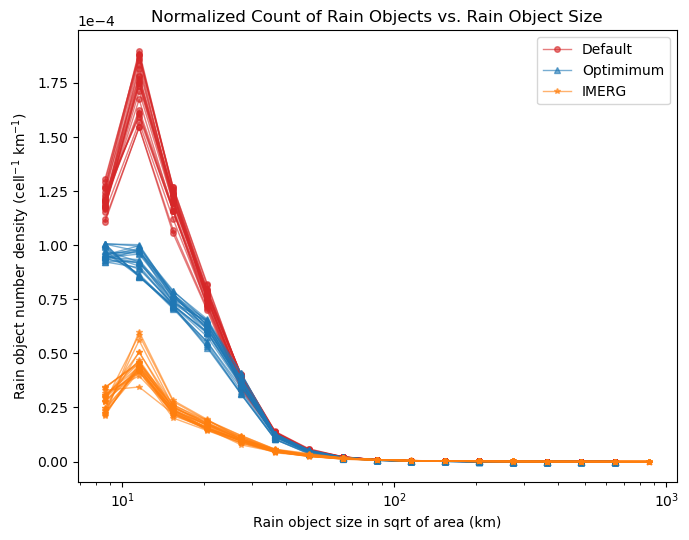

In [ ]:
# 60S-60N (|lat| <= 60), objects per grid cell vs. object size
plot_size_per_cell(BANDS[60])

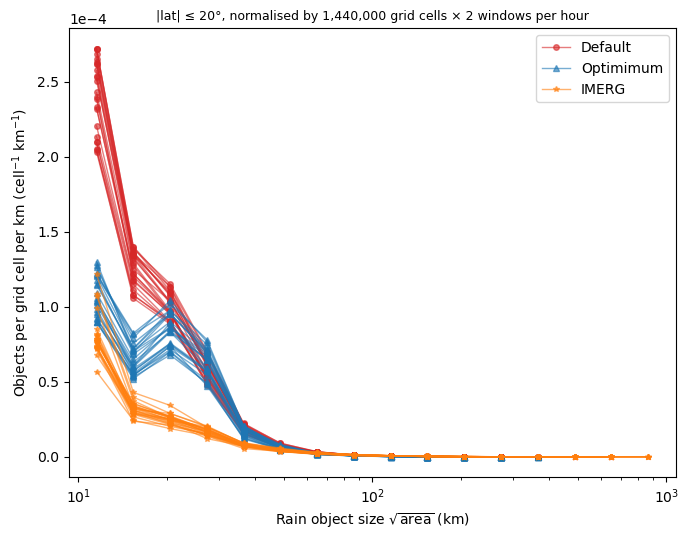

In [ ]:
# 20S-20N (|lat| <= 20), objects per grid cell vs. object size
plot_size_per_cell(BANDS[20])

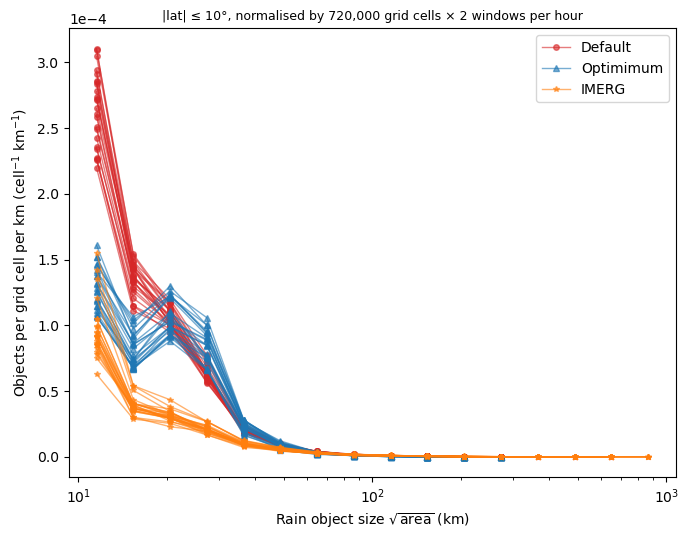

In [ ]:
# 10S-10N (|lat| <= 10), objects per grid cell vs. object size
plot_size_per_cell(BANDS[10])